In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from personality.config import DATA_PATH, ITEM_COLS, TARGET, CLASS_ORDER, AGE_MAX
from personality.plot_style import apply_style, CLASS_COLORS, save_fig

pd.set_option("display.float_format", "{:.1f}".format)


apply_style()
df = pd.read_csv(DATA_PATH) #project dataset
df.shape

(19719, 23)

In [16]:
#Hilfsfunktionen
def as_percent(p):
    """Formatiert einen Anteil (0 bis 1) als Prozent-Text, z. B. 0.4286 -> '42.9 %'."""
    return f"{p * 100:.1f} %"


In [17]:

print("Shape:", df.shape)
class_share = df[TARGET].value_counts(normalize=True)
print(class_share.map(as_percent))
df.head()

Shape: (19719, 23)
target
Moderate           42.9 %
Resilient          31.3 %
Overcontroller     14.3 %
Undercontroller    11.5 %
Name: proportion, dtype: str


,N6,N8,N7,N1,N9,N10,N3,N5,E3,N2,...,E4,age,C4,E1,A4,E10,E9,gender,hand,target
0,1,1,1,1,1,1,2,1,5,5,...,2,53,1,4,5,1,5,Male,Right,Resilient
1,4,2,3,2,2,4,4,3,3,3,...,3,46,2,2,4,5,1,Female,Right,Moderate
2,5,5,5,5,5,5,5,5,1,1,...,4,14,1,5,5,1,5,Female,Right,Moderate
3,5,5,5,5,4,5,4,4,2,4,...,4,19,5,2,4,5,4,Female,Right,Overcontroller
4,3,3,3,3,3,4,3,3,3,3,...,3,25,3,3,5,5,3,Female,Right,Moderate


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19719 entries, 0 to 19718
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   N6      19719 non-null  int64
 1   N8      19719 non-null  int64
 2   N7      19719 non-null  int64
 3   N1      19719 non-null  int64
 4   N9      19719 non-null  int64
 5   N10     19719 non-null  int64
 6   N3      19719 non-null  int64
 7   N5      19719 non-null  int64
 8   E3      19719 non-null  int64
 9   N2      19719 non-null  int64
 10  E5      19719 non-null  int64
 11  N4      19719 non-null  int64
 12  E7      19719 non-null  int64
 13  E4      19719 non-null  int64
 14  age     19719 non-null  int64
 15  C4      19719 non-null  int64
 16  E1      19719 non-null  int64
 17  A4      19719 non-null  int64
 18  E10     19719 non-null  int64
 19  E9      19719 non-null  int64
 20  gender  19695 non-null  str  
 21  hand    19619 non-null  str  
 22  target  19719 non-null  str  
dtypes: int64(20), str(3)
m

gender (24) and hand (100) have missing values, so the pipeline needs an imputer for them. gender, hand and target are text columns, everything else is numeric. gender and hand need encoding.

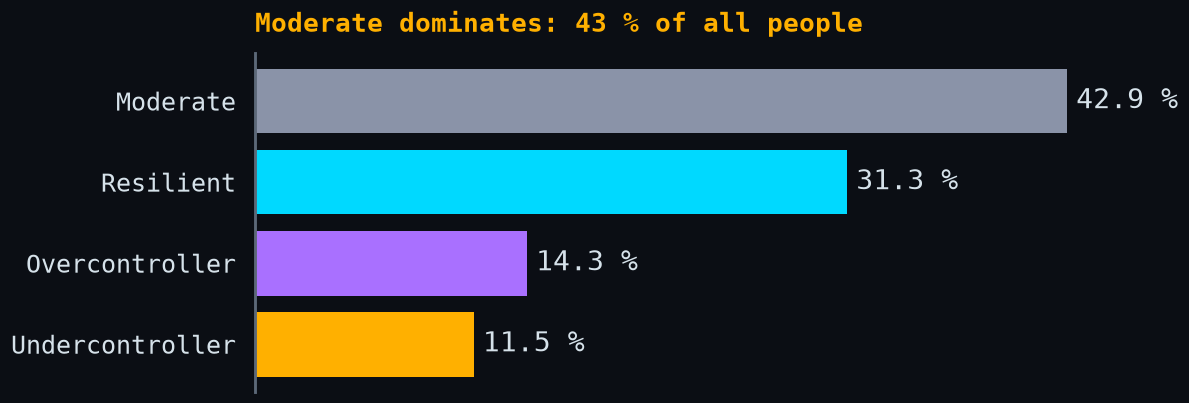

In [19]:
# Class distribution
shares = class_share.reindex(CLASS_ORDER)
colors = [CLASS_COLORS[c] for c in CLASS_ORDER]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(shares.index, shares, color=colors)
ax.bar_label(bars, labels=shares.map(as_percent), padding=6)

ax.invert_yaxis()
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Moderate dominates: 43 % of all people")

save_fig(fig, "01_class_distribution")

Classes are imbalanced. A model that always predicts “Moderate” would already reach 43 % accuracy, so accuracy is misleading and macro F1 is used as the main metric.

In [20]:
df["age"].describe()

count       19719.0
mean        50767.0
std       7121271.9
min            13.0
25%            18.0
50%            22.0
75%            31.0
max     999999999.0
Name: age, dtype: float64

In [27]:
len(df[df["age"] > AGE_MAX])

83

In [31]:
df[df["age"]>AGE_MAX].sort_values("age")

,N6,N8,N7,N1,N9,N10,N3,N5,E3,N2,...,E4,age,C4,E1,A4,E10,E9,gender,hand,target
18998,2,2,2,4,2,4,5,2,4,3,...,1,118,4,4,5,2,5,Female,Right,Moderate
15060,4,4,4,5,4,4,5,4,3,1,...,2,188,3,4,4,2,2,Female,Both,Moderate
15986,3,3,2,4,3,3,5,3,3,4,...,4,188,3,1,5,4,2,Female,Right,Moderate
15941,5,3,3,1,5,5,4,1,1,4,...,5,191,3,1,4,5,1,Male,Right,Undercontroller
5043,4,3,3,3,3,2,5,2,5,3,...,4,208,3,3,5,2,5,Female,Right,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19614,2,2,4,2,5,2,1,4,5,4,...,1,1998,3,5,1,2,5,Male,Both,Undercontroller
1649,2,1,3,2,4,2,3,2,2,4,...,3,1999,2,3,3,5,4,Male,Right,Resilient
10715,1,1,1,2,1,1,1,1,1,3,...,1,2000,1,5,1,1,5,Male,Right,Resilient
9987,1,1,1,3,3,1,4,1,2,4,...,5,412434,2,3,5,5,2,Other,Both,Resilient


### Data quality: age

`age` has no missing values, but 83 rows contain invalid values above 100:
- Most of them look like **birth years** (1961 to 2000), so participants misunderstood the field.
- A few are clear garbage entries (e.g. 188, 412434, 999999999).

**Decision:** All ages above `AGE_MAX` are set to `NaN` and imputed with the median inside the pipeline.
Converting birth years to ages would require guessing the survey year, which is not worth it for 83 of ~19,700 rows (0.4 %).
The median is robust against these outliers, unlike the mean.

In [34]:
df[(df[ITEM_COLS] == 0).any(axis=1)]

,N6,N8,N7,N1,N9,N10,N3,N5,E3,N2,...,E4,age,C4,E1,A4,E10,E9,gender,hand,target
19064,0,0,0,0,0,0,0,0,0,0,...,0,52,0,0,0,0,0,Female,Right,Resilient


### Data quality: invalid answers

One row has `0` for all 19 questions, which is outside the 1 to 5 scale.
This person effectively did not answer the questionnaire.

**Decision:** This row is dropped before modeling. Imputing 19 missing answers would add no real information.

In [36]:
df.duplicated().sum()

np.int64(3)

### Data quality: duplicates

3 rows are exact duplicates (all 22 features and the target are identical).
Most likely the questionnaire was submitted twice.

**Decision:** Duplicates are dropped. Otherwise one copy could end up in the training set and the other in the test set, which would make the test score slightly too optimistic (data leakage).

In [ ]:
## EDA summary

| Issue | Rows | Handled by |
|---|---|---|
| `age` above 100 (birth years, garbage) | 83 | Cleaning: set to `NaN` |
| All answers `0` | 1 | Cleaning: drop row |
| Exact duplicates | 3 | Cleaning: drop rows |
| Missing `gender` / `hand` | 24 / 100 | Pipeline: impute most frequent |
| Missing `age` (after cleaning) | 83 | Pipeline: impute median |
| Text columns `gender`, `hand` | all | Pipeline: one-hot encoding |
| Different scales (`age` vs. 1 to 5) | all | Pipeline: standard scaling |

**Cleaning** runs once on the raw training data. It removes rows that carry no valid information.
**The pipeline** runs on every input, in training and in the app. It never drops rows, it only prepares them.

**App:** Inputs are restricted to the valid ranges (`AGE_MIN` to `AGE_MAX`, answers 1 to 5), using the same limits from `config.py`. The pipeline still handles missing values as a safety net.

**Target:** Classes are imbalanced (Moderate 43 %). Accuracy is misleading, so **macro F1** is the main metric and the train/test split is stratified.